<a href="https://colab.research.google.com/github/aditiAD1251/-Recovery-Management-System/blob/main/ML_NB_ACT_1(AD3270).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning CIE 2 – Activity 1: Dataset Preparation

**Dataset:** Crop Recommendation (`Crop_recommendation.csv`)

**Objective:** Check the dataset, find data-quality problems, create graphs, clean the data, encode the crop names, scale numerical columns and save a prepared CSV file.


## Step 1 – Select and understand the dataset

**Dataset description:** The Crop Recommendation dataset contains soil nutrient measurements and environmental conditions for different crops. Each row represents one observation, and `label` gives the crop associated with those conditions.

**Source:** [Crop Recommendation Dataset – Kaggle](https://www.kaggle.com/datasets/atharvaingle/crop-recommendation-dataset)  
**File type:** CSV  



In [3]:
# Step 1: Import libraries and load the dataset

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('Crop_recommendation.csv')

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)


Dataset loaded successfully!
Rows and columns: (2200, 8)


## Step 2 – Load and inspect the dataset


In [4]:
# Display first 5 rows
print("First 5 rows:")
display(df.head())

# Display last 5 rows
print("Last 5 rows:")
display(df.tail())

# Display column names
print("Column names:")
print(df.columns)

# Display data types
print("Data types:")
print(df.dtypes)

# Display dataset information
df.info()


First 5 rows:


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


Last 5 rows:


,N,P,K,temperature,humidity,ph,rainfall,label
2195,107,34,32,26.774637,66.413269,6.780064,177.774507,coffee
2196,99,15,27,27.417112,56.636362,6.086922,127.924610,coffee
2197,118,33,30,24.131797,67.225123,6.362608,173.322839,coffee
2198,117,32,34,26.272418,52.127394,6.758793,127.175293,coffee
2199,104,18,30,23.603016,60.396475,6.779833,140.937041,coffee


Column names:
Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='object')
Data types:
N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label           object
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


### What the columns represent

- `N`: Nitrogen content in the soil.
- `P`: Phosphorus content in the soil.
- `K`: Potassium content in the soil.
- `temperature`: Temperature of the environment.
- `humidity`: Relative humidity.
- `ph`: Soil pH value.
- `rainfall`: Rainfall amount.
- `label`: Crop category / recommended crop.

**Dataset understanding:** The seven measurement columns are numerical input features. `label` is a categorical column and can be considered the target for a future crop-classification task.


## Step 3 – Identify data types and basic statistics




In [5]:
# Separate numerical and categorical columns

numerical_columns = df.select_dtypes(include='number').columns
categorical_columns = df.select_dtypes(include='object').columns

print("Numerical columns:")
print(list(numerical_columns))

print("\nCategorical columns:")
print(list(categorical_columns))

# Summary of numerical columns
print("\nBasic statistics:")
display(df.describe())

# Count the number of records for each crop
print("\nCrop counts:")
display(df['label'].value_counts())

# The label column can be the target in a future prediction task
print("\nPossible target column: label")


Numerical columns:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

Categorical columns:
['label']

Basic statistics:


,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117



Crop counts:


,count
label,
rice,100
maize,100
chickpea,100
kidneybeans,100
pigeonpeas,100
mothbeans,100
mungbean,100
blackgram,100
lentil,100



Possible target column: label


**Observation:** `label` is the possible target column. The columns `N`, `P`, `K`, `temperature`, `humidity`, `ph` and `rainfall` can be used as input features. There is no ID column in this file. Values should be interpreted in the context of the dataset; unusual values should be investigated rather than automatically deleted.


## Step 4 – Identify missing values



In [6]:
# Check missing values in every column

print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

# Calculate missing-value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing-value percentage:")
print(missing_percentage.round(2))


Missing values in each column:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Total missing values:
0

Missing-value percentage:
N              0.0
P              0.0
K              0.0
temperature    0.0
humidity       0.0
ph             0.0
rainfall       0.0
label          0.0
dtype: float64


**Finding:** Use the missing-value report above to identify which columns contain missing values. If the total missing cells are zero, no imputation is needed. If missing values are present, they are handled in Step 5.


## Step 5 – Handle missing values




In [7]:
# Make a copy so the original data is not changed
clean_df = df.copy()

# Fill missing numerical values with the median
clean_df['N'] = clean_df['N'].fillna(clean_df['N'].median())
clean_df['P'] = clean_df['P'].fillna(clean_df['P'].median())
clean_df['K'] = clean_df['K'].fillna(clean_df['K'].median())
clean_df['temperature'] = clean_df['temperature'].fillna(clean_df['temperature'].median())
clean_df['humidity'] = clean_df['humidity'].fillna(clean_df['humidity'].median())
clean_df['ph'] = clean_df['ph'].fillna(clean_df['ph'].median())
clean_df['rainfall'] = clean_df['rainfall'].fillna(clean_df['rainfall'].median())

# Fill missing crop names with the most common crop name
clean_df['label'] = clean_df['label'].fillna(clean_df['label'].mode()[0])

print("Missing values after cleaning:")
print(clean_df.isnull().sum())


Missing values after cleaning:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64


**Explanation:** No values were filled because the uploaded file already has complete records. This is the correct decision; we should not create artificial missing values just to demonstrate imputation.


## Step 6 – Check duplicate records and consistency



In [8]:
# Check duplicate rows
print("Number of duplicate rows:", clean_df.duplicated().sum())

# Remove duplicate rows
clean_df = clean_df.drop_duplicates()

print("Duplicate rows after removal:", clean_df.duplicated().sum())

# Display crop names to check whether they are written consistently
print("Crop names:")
print(clean_df['label'].unique())


Number of duplicate rows: 0
Duplicate rows after removal: 0
Crop names:
['rice' 'maize' 'chickpea' 'kidneybeans' 'pigeonpeas' 'mothbeans'
 'mungbean' 'blackgram' 'lentil' 'pomegranate' 'banana' 'mango' 'grapes'
 'watermelon' 'muskmelon' 'apple' 'orange' 'papaya' 'coconut' 'cotton'
 'jute' 'coffee']


**Finding:** The duplicate count shows whether repeated rows were present. Duplicate rows are removed because they repeat the same observation. The crop names are displayed so their spelling can be checked. No automatic text conversion is applied to the crop names.


## Step 7 – Perform basic exploratory data analysis (EDA)



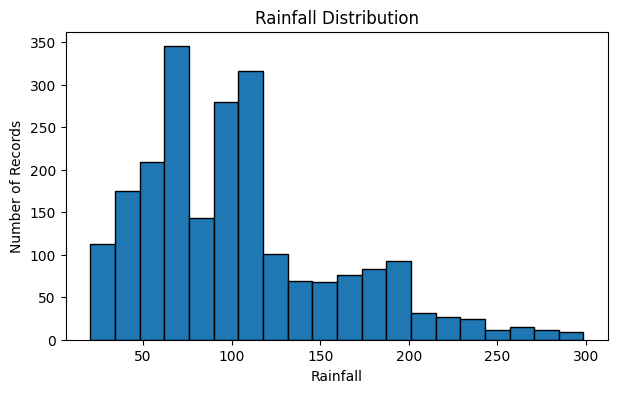

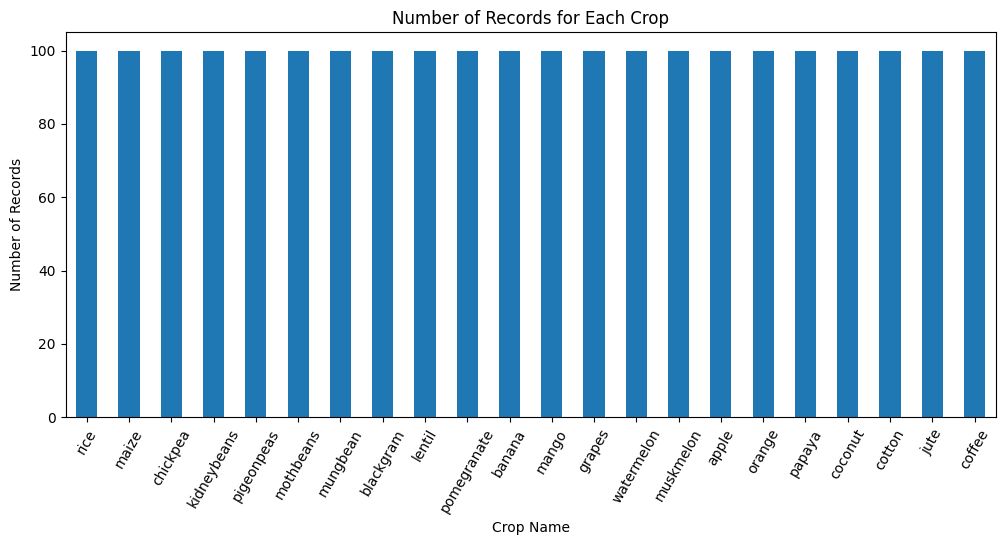

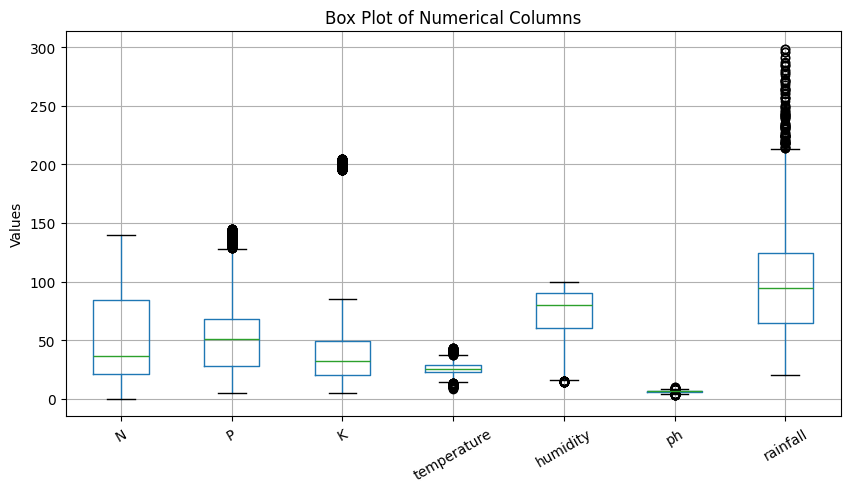

,count
label,
rice,100
maize,100
chickpea,100
kidneybeans,100
pigeonpeas,100
mothbeans,100
mungbean,100
blackgram,100
lentil,100


In [9]:
# Import plotting library
import matplotlib.pyplot as plt

# 1. Histogram: distribution of rainfall
plt.figure(figsize=(7, 4))
plt.hist(clean_df['rainfall'], bins=20, edgecolor='black')
plt.title('Rainfall Distribution')
plt.xlabel('Rainfall')
plt.ylabel('Number of Records')
plt.show()

# 2. Bar chart: number of records for each crop
crop_counts = clean_df['label'].value_counts()

plt.figure(figsize=(12, 5))
crop_counts.plot(kind='bar')
plt.title('Number of Records for Each Crop')
plt.xlabel('Crop Name')
plt.ylabel('Number of Records')
plt.xticks(rotation=60)
plt.show()

# 3. Box plot: check spread and possible outliers
plt.figure(figsize=(10, 5))
clean_df[['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']].boxplot()
plt.title('Box Plot of Numerical Columns')
plt.ylabel('Values')
plt.xticks(rotation=30)
plt.show()

# Display crop frequency table
display(crop_counts)


### EDA observations

1. The histogram shows how rainfall values are distributed in the dataset.
2. The bar chart shows how many records are available for each crop.
3. The box plot shows the spread of numerical values and may highlight possible outliers.

Write your observations after looking at the graphs. Do not remove unusual values without checking them first.


## Step 8 – Encode categorical features



In [10]:
# Convert crop names into numbers

from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

clean_df['label_encoded'] = encoder.fit_transform(clean_df['label'])

print("Crop names and their encoded numbers:")
for crop, number in zip(encoder.classes_, encoder.transform(encoder.classes_)):
    print(crop, "=", number)

print("\nBefore and after encoding:")
display(clean_df[['label', 'label_encoded']].head())


Crop names and their encoded numbers:
apple = 0
banana = 1
blackgram = 2
chickpea = 3
coconut = 4
coffee = 5
cotton = 6
grapes = 7
jute = 8
kidneybeans = 9
lentil = 10
maize = 11
mango = 12
mothbeans = 13
mungbean = 14
muskmelon = 15
orange = 16
papaya = 17
pigeonpeas = 18
pomegranate = 19
rice = 20
watermelon = 21

Before and after encoding:


,label,label_encoded
0,rice,20
1,rice,20
2,rice,20
3,rice,20
4,rice,20


**Explanation:** For example, each crop name is assigned a numeric class code. The code is only an identifier for the category; it does not mean that one crop is greater or better than another. No input feature needs one-hot encoding in this dataset.


## Step 9 – Scale numerical features where appropriate



In [11]:
# Scale numerical input columns using StandardScaler

from sklearn.preprocessing import StandardScaler

feature_columns = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

scaler = StandardScaler()

scaled_values = scaler.fit_transform(clean_df[feature_columns])

# Convert scaled values into a DataFrame
scaled_df = pd.DataFrame(scaled_values, columns=feature_columns)

print("Original numerical values:")
display(clean_df[feature_columns].head())

print("Scaled numerical values:")
display(scaled_df.head())


Original numerical values:


,N,P,K,temperature,humidity,ph,rainfall
0,90,42,43,20.879744,82.002744,6.502985,202.935536
1,85,58,41,21.770462,80.319644,7.038096,226.655537
2,60,55,44,23.004459,82.320763,7.840207,263.964248
3,74,35,40,26.491096,80.158363,6.980401,242.864034
4,78,42,42,20.130175,81.604873,7.628473,262.717340


Scaled numerical values:


,N,P,K,temperature,humidity,ph,rainfall
0,1.068797,-0.344551,-0.101688,-0.935587,0.472666,0.043302,1.810361
1,0.933329,0.140616,-0.141185,-0.759646,0.397051,0.734873,2.242058
2,0.255986,0.049647,-0.081939,-0.515898,0.486954,1.771510,2.921066
3,0.635298,-0.556811,-0.160933,0.172807,0.389805,0.660308,2.537048
4,0.743673,-0.344551,-0.121436,-1.083647,0.454792,1.497868,2.898373


**Scaling method selected:** StandardScaler (standardisation). The seven numerical input features are scaled because their ranges differ. The target `label` / `label_encoded` is not scaled.


## Step 10 – Save the prepared dataset




In [12]:
# Add crop name and encoded crop number to the scaled data

prepared_df = scaled_df.copy()

prepared_df['label'] = clean_df['label'].values
prepared_df['label_encoded'] = clean_df['label_encoded'].values

print("Final dataset shape:", prepared_df.shape)

print("\nMissing values:")
print(prepared_df.isnull().sum().sum())

print("\nDuplicate rows:")
print(prepared_df.duplicated().sum())

print("\nFirst 5 rows of prepared dataset:")
display(prepared_df.head())

# Save the prepared dataset as a CSV file
prepared_df.to_csv('Crop_Recommendation_Prepared.csv', index=False)

print("Prepared dataset saved successfully!")
print("File name: Crop_Recommendation_Prepared.csv")
print("Download it from the Files panel on the left in Google Colab.")


Final dataset shape: (2200, 9)

Missing values:
0

Duplicate rows:
0

First 5 rows of prepared dataset:


,N,P,K,temperature,humidity,ph,rainfall,label,label_encoded
0,1.068797,-0.344551,-0.101688,-0.935587,0.472666,0.043302,1.810361,rice,20
1,0.933329,0.140616,-0.141185,-0.759646,0.397051,0.734873,2.242058,rice,20
2,0.255986,0.049647,-0.081939,-0.515898,0.486954,1.771510,2.921066,rice,20
3,0.635298,-0.556811,-0.160933,0.172807,0.389805,0.660308,2.537048,rice,20
4,0.743673,-0.344551,-0.121436,-1.083647,0.454792,1.497868,2.898373,rice,20


Prepared dataset saved successfully!
File name: Crop_Recommendation_Prepared.csv
Download it from the Files panel on the left in Google Colab.


In [13]:
from google.colab import files

files.download('Crop_Recommendation_Prepared.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion

In this activity, the Crop Recommendation dataset was loaded and inspected using Pandas. We checked the rows, columns, data types, summary statistics and missing values.

We handled missing values, checked and removed duplicate rows, and corrected the format of crop names. We performed basic EDA using a histogram, bar chart and box plot.

The crop names were converted into numbers using Label Encoding. The numerical input columns were scaled using StandardScaler. Finally, the dataset is prepared.
